# SOM visualization for unlabeled KiDS inference data

The figures below show the number of inference objects and their mean `r_mag` in each SOM cell. Empty SOM cells are shown in white.


In [1]:
from joblib import load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from kids.catalog.features import CLF_FEATURES
from kids.catalog.preparation import load_and_prepare_inference_catalog
from kids.ml.som.som import MySOM


In [ ]:
DATA_PATH = '../data/KiDS_DR5_WCScut_columns_15MLN.csv'
SOM_PATH = '../saved_models/som/som_best.pth'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SOM_CONFIG = {
    'x': 60, 'y': 60, 'num_features': len(CLF_FEATURES), 'epochs': 35,
    'batch_size': 4 * 1024, 'learning_rate': 0.8, 'sigma': 35,
    'device': DEVICE, 'topology': 'rectangular', 'pbc': True,
    'lr_decay_function': 'asymptotic_decay',
    'sigma_decay_function': 'lr_linear_decay_to_zero',
    'neighborhood_function': 'gaussian', 'distance_function': 'euclidean',
    'initialization_mode': 'pca',
}
raw_data = load_and_prepare_inference_catalog(DATA_PATH)
preprocessor = load('../saved_models/som/preprocessor_som_best.joblib')
som = MySOM(**SOM_CONFIG)
som.load_state_dict(torch.load(SOM_PATH, map_location=DEVICE, weights_only=True))
som.eval()
assert tuple(som.weights.shape) == (SOM_CONFIG['x'], SOM_CONFIG['y'], len(CLF_FEATURES))


In [3]:
BATCH_SIZE = 1024
n_x, n_y = SOM_CONFIG['x'], SOM_CONFIG['y']
cell_count = np.zeros(n_x * n_y, dtype=np.int64)
r_mag_sum = np.zeros(n_x * n_y, dtype=np.float64)
r_mag_count = np.zeros(n_x * n_y, dtype=np.int64)
feature_data = raw_data.loc[:, CLF_FEATURES]
r_mag = raw_data['MAG_GAAP_r'].to_numpy(dtype=np.float64)

with torch.no_grad():
    for start in range(0, len(feature_data), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(feature_data))
        X_batch = preprocessor.transform(feature_data.iloc[start:stop])
        X_tensor = torch.as_tensor(X_batch, dtype=torch.float32, device=DEVICE)
        batch_bmus = som.identify_bmus(X_tensor).cpu().numpy()
        batch_cell_id = batch_bmus[:, 0] * n_y + batch_bmus[:, 1]
        cell_count += np.bincount(batch_cell_id, minlength=n_x * n_y)
        batch_r_mag = r_mag[start:stop]
        valid_r_mag = np.isfinite(batch_r_mag)
        r_mag_sum += np.bincount(
            batch_cell_id[valid_r_mag],
            weights=batch_r_mag[valid_r_mag],
            minlength=n_x * n_y,
        )
        r_mag_count += np.bincount(
            batch_cell_id[valid_r_mag], minlength=n_x * n_y
        )


In [4]:
occupied = cell_count > 0
cell_ids = np.flatnonzero(occupied)
cell_stats = pd.DataFrame({
    'count': cell_count[occupied],
    'mean_r_mag': np.divide(
        r_mag_sum[occupied],
        r_mag_count[occupied],
        out=np.full(cell_ids.size, np.nan),
        where=r_mag_count[occupied] > 0,
    ),
    'bmu_x': cell_ids // n_y,
    'bmu_y': cell_ids % n_y,
}, index=cell_ids)
assert cell_stats['count'].sum() == len(raw_data)
assert np.isfinite(cell_stats.loc[r_mag_count[occupied] > 0, 'mean_r_mag']).all()


In [5]:
from pathlib import Path
import re

FIG_DIR = Path('../figs/KiDS')
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _figure_path(title):
    slug = re.sub(r'[^a-z0-9]+', '_', title.lower()).strip('_')
    return FIG_DIR / f'{slug}.png'


def plot_cell_map(values, title, *, cmap='viridis', vmin=None, vmax=None, center=None):
    values = np.asarray(values)
    if values.shape == (n_x, n_y):
        grid = values.copy()
    else:
        if values.size != len(cell_stats):
            raise ValueError(
                f'Expected one value per occupied cell ({len(cell_stats)}) '
                f'or a full SOM grid ({n_x}, {n_y}); got {values.shape}.'
            )
        grid = np.full((n_x, n_y), np.nan)
        grid[cell_stats['bmu_x'].to_numpy(dtype=int), cell_stats['bmu_y'].to_numpy(dtype=int)] = values
    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    if center is not None:
        limit = max(abs(np.nanmin(grid - center)), abs(np.nanmax(grid - center)))
        vmin, vmax = center - limit, center + limit
    image = ax.imshow(grid.T, origin='lower', interpolation='nearest', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set(title=title, xlabel='SOM x', ylabel='SOM y')
    fig.colorbar(image, ax=ax, label=title)
    fig.savefig(_figure_path(title), dpi=150)
    plt.show()


def plot_som_component(feature_name):
    if feature_name not in CLF_FEATURES:
        raise ValueError(f'{feature_name!r} is not a feature in the saved SOM.')
    plot_cell_map(som.weights[:, :, CLF_FEATURES.index(feature_name)].cpu().numpy(),
                  f'SOM component plane: {feature_name}', cmap='coolwarm')


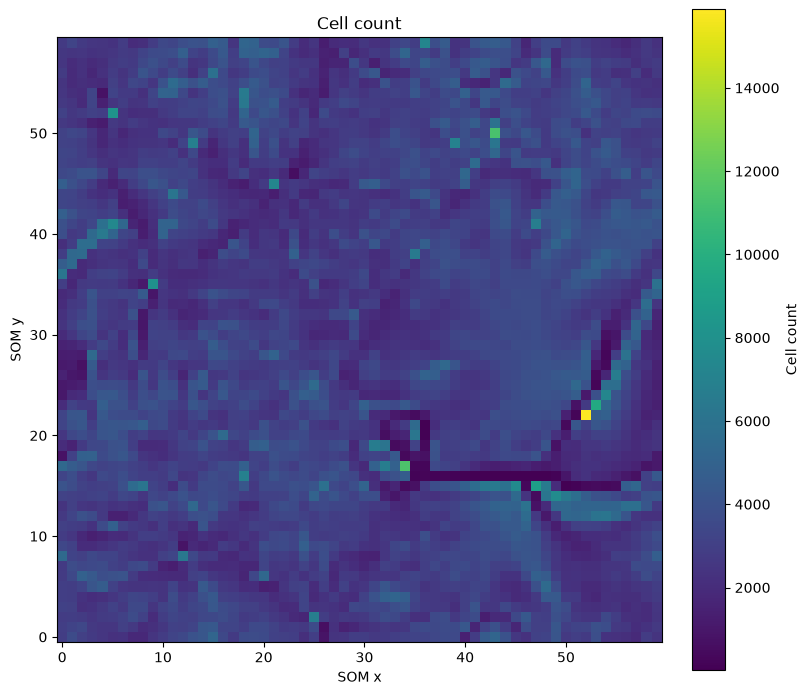

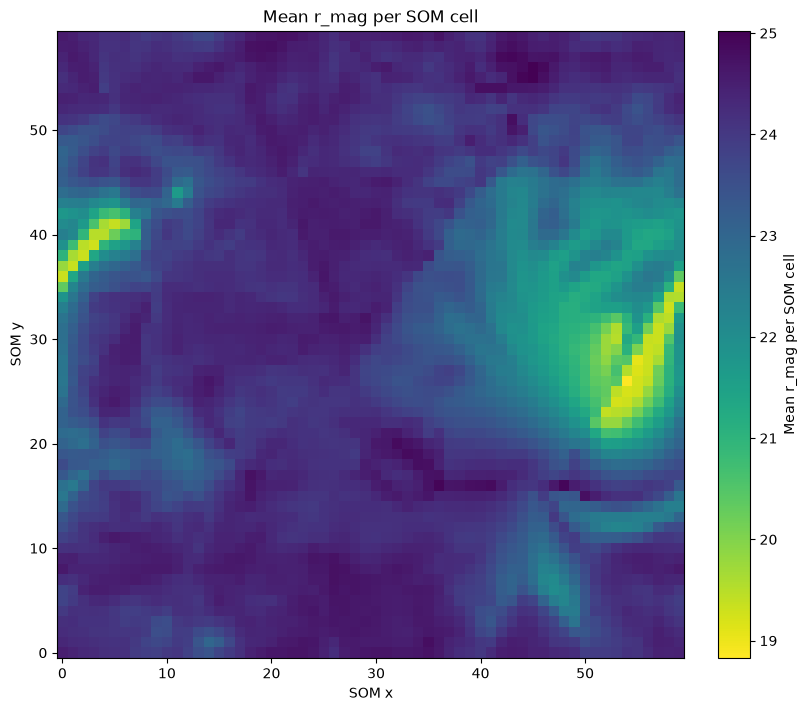

In [6]:
plot_cell_map(cell_stats['count'], 'Cell count', cmap='viridis')
plot_cell_map(cell_stats['mean_r_mag'], 'Mean r_mag per SOM cell', cmap='viridis_r')


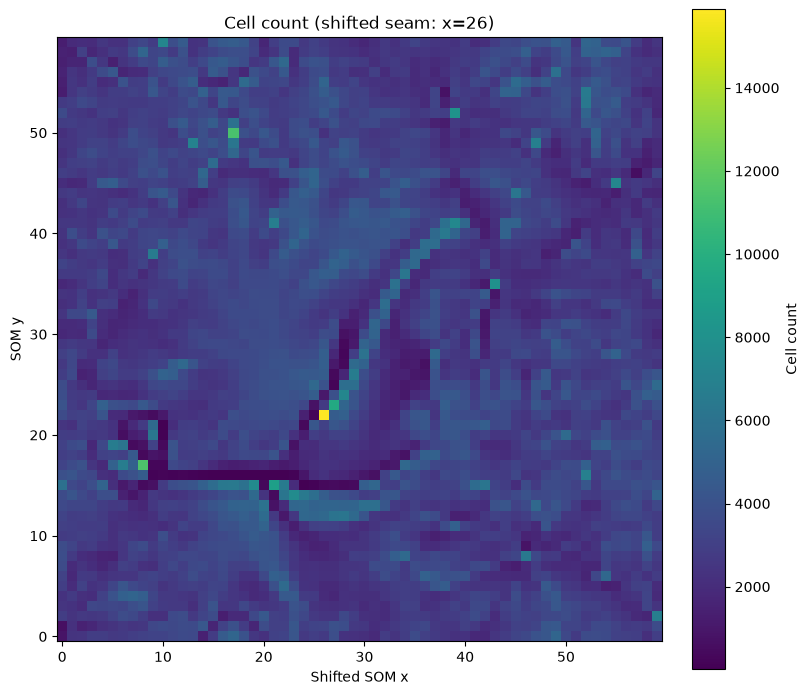

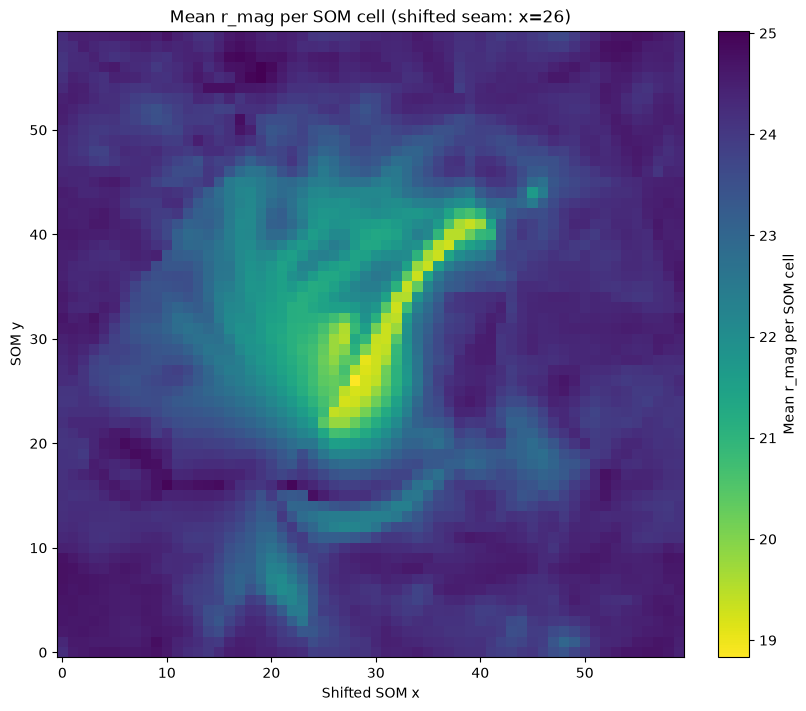

In [7]:
def _shifted_cell_grid(values):
    values = np.asarray(values)
    if values.size != len(cell_stats):
        raise ValueError(
            f'Expected one value per occupied cell ({len(cell_stats)}); '
            f'got {values.shape}.'
        )
    grid = np.full((n_x, n_y), np.nan)
    grid[cell_stats['bmu_x'].to_numpy(dtype=int), cell_stats['bmu_y'].to_numpy(dtype=int)] = values
    return grid


def plot_shifted_cell_map(values, title, *, cmap='viridis', vmin=None, vmax=None):
    grid = _shifted_cell_grid(values)
    population_grid = np.zeros((n_x, n_y))
    population_grid[cell_stats['bmu_x'].to_numpy(dtype=int), cell_stats['bmu_y'].to_numpy(dtype=int)] = cell_stats['count']
    column_population = population_grid.sum(axis=1)
    seam = int(np.argmin(column_population))
    shifted_grid = np.roll(grid, -seam, axis=0)
    fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
    image = ax.imshow(
        shifted_grid.T, origin='lower', interpolation='nearest',
        cmap=cmap, vmin=vmin, vmax=vmax,
    )
    ax.set(
        title=f'{title} (shifted seam: x={seam})',
        xlabel='Shifted SOM x', ylabel='SOM y',
    )
    fig.colorbar(image, ax=ax, label=title)
    fig.savefig(_figure_path(f'{title} shifted'), dpi=150)
    plt.show()


plot_shifted_cell_map(cell_stats['count'], 'Cell count', cmap='viridis')
plot_shifted_cell_map(cell_stats['mean_r_mag'], 'Mean r_mag per SOM cell', cmap='viridis_r')


In [8]:
assert raw_data.shape[0] * raw_data.shape[1] == raw_data.size